In [345]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import random
import math


## Run a Simulation One Step 

### Setting Up Graphs

Because we want to implement games on multiple type of graphs I am creating a function that can intake params to create three types of graphs: random, scale-free, and 2d lattices. 

In [346]:
def setup_graph(network_type, N, p = None, m = None):
    '''
    A function to setup the initial graphs for running games on networks. 
    '''
    # A list of Graph typologies to choose from. Here, we will only use three: random, scale-free, and a lattice.
    network_types = ["random", "scale-free", "lattice"]

    # If an invalid network type is entered raise a ValueError and give a list of valid values.
    if network_type not in network_types:
        raise ValueError(f"Unknown network type {network_type}. Choose one of: random, scale-free, lattice.")

    # Creating an Erdos-Renyi Graph
    if network_type == "random":

        # If the probability value is empty, raise a value error with a message. 
        if p is None:
            raise ValueError("For an Erdos-Renyi graph you must enter a valid value for p.")
        
        # If the probability value is lesser than zero or greater than 1.
        elif not (0 <= p < 1):
            raise ValueError(f"Your probability value ({p}) is invalid; choose a value in [0, 1).")

        # Otherwise, generate an Erdos-Renyi graph
        else:
            G = nx.erdos_renyi_graph(n = N, p = p)

    # Creating a Scale-Free Network
    elif network_type == "scale-free":
        # If m is None raise a value error.
        if m is None:
            raise ValueError(f"For an Barabasi-Albert graph you must enter a valid value for m.")
        
        # If m is lesser than one raise a value error.
        elif not (1 <= m < N):
            raise ValueError(f"For a Barabasi-Albert graph, m must be an integer from 1 to {N - 1}; got {m}.")
        
        # Otherwise, generate a Scale-Free Network
        else:
            G = nx.barabasi_albert_graph(n = N, m = m)

    # Creating a 2D Lattice
    elif network_type == "lattice":
        # 2D lattice needs to be a perfect square
        side = math.isqrt(N)

        # If N isn't a perfect square, raise a ValueError
        if side * side != N:
            raise ValueError(f"For a lattice, N must be a perfect square (e.g., 100, 400); got {N}.")
        
        # Otherwise create a 2D Lattice Graph
        else:
            G = nx.grid_2d_graph(side, side)

            G = nx.convert_node_labels_to_integers(G) # Convert Node labels to integers and not position
    return G

In [347]:
G = setup_graph(network_type="scale-free", N=500, m=4)

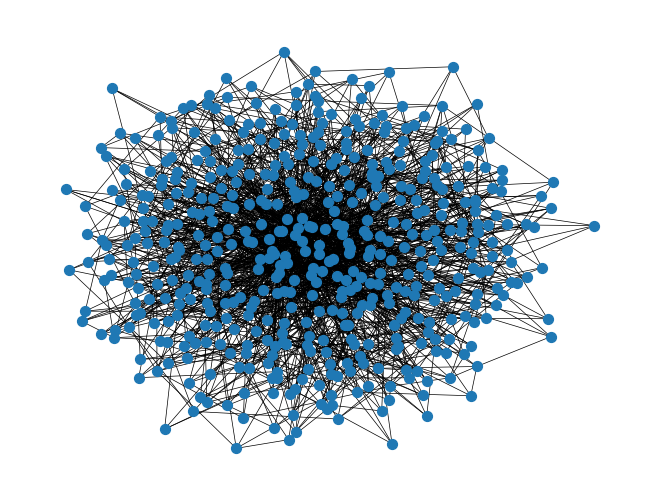

In [348]:
nx.draw(G,
        node_size=50,
        width=0.5)

In [349]:
def setup_params(G, share):
    '''
    
    '''

    # Keeping a number of all nodes in the graph.
    num_nodes = len(G.nodes())

    # In the Prisoner's Dilemma set up there are two groups: Cooperators and Defections
    group_params = {'C': {'color': "tab:blue", "payoff": 0}, 'D': {'color': 'tab:red', "payoff": 0}}

    # Population shares for each group (Must sum to 1)
    population_shares = {'C': share, 'D': 1 - share}

    # Create dictionary of agents
    agents = {}

    # Get list of all nodes or agents
    all_nodes = list(G.nodes())

    # Calculate how many agents per group using the items in Population shares
    n_agents_per_group = {}

    for group, pop_share in population_shares.items():
        n_agents_per_group[group] = round(num_nodes * pop_share)

    # Shuffle nodes so agents are randomly placed
    random.shuffle(all_nodes)

    # Assign agents to groups
    node_index = 0
    for group, n_agents in n_agents_per_group.items():
        params = group_params[group]

        for i in range(n_agents):
            node = all_nodes[node_index]

            # Create agent with their group and color
            agents[node] = {
                'group': group,
                'color': params['color'],
                'payoff': params['payoff']
            }

            node_index += 1

    nx.set_node_attributes(G, agents)

    return agents


In [350]:
agents = setup_params(G, 0.55)

G.nodes

NodeView((0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 

In [351]:
colors
payoffs

[0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,


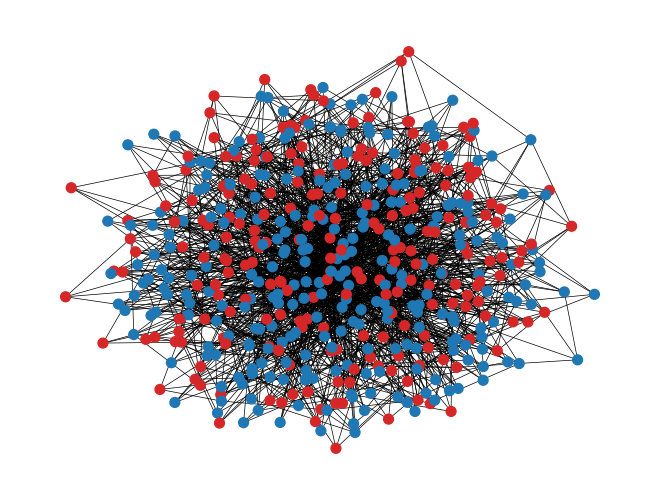

In [352]:
payoffs = [G.nodes[n]["payoff"] for n in G.nodes]
colors = [G.nodes[n]["color"] for n in G.nodes]
nx.draw(G, node_color=colors, node_size=50, width=0.5)

In [353]:
print("\nExample agents:")

for node in list(agents.keys())[:5]: # Loop through first 5 Agents
    agent = agents[node] # Get the values for this agent
    print(f"Agent {node}'s group is {agent['group']} and color is {agent['color']}")



Example agents:
Agent 50's group is C and color is tab:blue
Agent 269's group is C and color is tab:blue
Agent 401's group is C and color is tab:blue
Agent 423's group is C and color is tab:blue
Agent 134's group is C and color is tab:blue


In [354]:
N = len(G.nodes())
N

500

In [355]:
node_i = random.choice(list(G.nodes))

neighbors = list(G.neighbors(node_i))

In [356]:
neighbors

[2, 53, 78, 55, 122, 130, 309, 459]

### Running One Step of a Simulation

In [357]:
# Using Nowak's and May's Prisoner's Dilemma Values
b = 1

T, R, P, S = b, 1, 0, 0

In [358]:
new_strategies = {}

for node in G.nodes():
    neighbors = list(G.neighbors(node))

    n_coop = 0 # Number of Cooperators
    n_defect = 0 # Number of Defectors 

    for neighbor in neighbors:
        if G.nodes[neighbor]['group'] == 'C':
            n_coop = n_coop + 1
        if G.nodes[neighbor]['group'] == 'D':
            n_defect = n_defect + 1

    c_payoff = n_coop # Calculate Payoff for Cooperating

    d_payoff = b * n_coop # Calculate Payoff for Defection

    # Compare Payoffs and then
    if d_payoff > c_payoff:
        new_strategies[node] = 'D'

    elif d_payoff < c_payoff:
        new_strategies[node] = 'C'

    else:
        new_strategies[node] = G.nodes[node]['group']

    print(n_coop, n_defect, c_payoff, d_payoff)

len(new_strategies)

39 31 39 39
18 18 18 18
28 16 28 28
21 8 21 21
15 13 15 15
36 16 36 36
23 17 23 23
33 28 33 33
28 21 28 28
22 12 22 22
16 18 16 16
19 11 19 19
31 24 31 31
21 20 21 21
6 7 6 6
7 5 7 7
15 12 15 15
12 14 12 12
16 19 16 16
7 4 7 7
8 11 8 8
6 8 6 6
8 5 8 8
12 6 12 12
8 4 8 8
18 8 18 18
5 7 5 5
7 8 7 7
13 6 13 13
8 8 8 8
9 3 9 9
12 11 12 12
17 11 17 17
10 11 10 10
3 6 3 3
12 9 12 12
14 7 14 14
10 7 10 10
8 11 8 8
7 3 7 7
3 10 3 3
7 7 7 7
8 2 8 8
10 5 10 10
12 10 12 12
15 7 15 15
6 3 6 6
5 3 5 5
1 6 1 1
7 1 7 7
10 6 10 10
4 2 4 4
9 2 9 9
4 6 4 4
10 9 10 10
5 11 5 5
8 4 8 8
13 8 13 13
6 2 6 6
6 7 6 6
9 4 9 9
9 2 9 9
12 4 12 12
4 4 4 4
5 2 5 5
3 3 3 3
12 9 12 12
2 4 2 2
7 2 7 7
10 8 10 10
11 5 11 11
13 9 13 13
2 3 2 2
5 2 5 5
10 2 10 10
4 2 4 4
11 6 11 11
4 5 4 4
4 7 4 4
8 5 8 8
5 4 5 5
8 9 8 8
3 3 3 3
4 4 4 4
10 5 10 10
9 2 9 9
8 11 8 8
12 3 12 12
3 3 3 3
5 4 5 5
6 3 6 6
9 4 9 9
10 7 10 10
3 5 3 3
10 7 10 10
5 4 5 5
3 3 3 3
3 2 3 3
8 8 8 8
7 1 7 7
5 2 5 5
4 7 4 4
5 2 5 5
7 1 7 7
2 3 2 2
2 4 2 

500

In [359]:
neighbors
c_payoff

1

In [360]:
new_strategies

{0: 'D',
 1: 'C',
 2: 'C',
 3: 'C',
 4: 'D',
 5: 'C',
 6: 'C',
 7: 'C',
 8: 'D',
 9: 'C',
 10: 'D',
 11: 'C',
 12: 'C',
 13: 'C',
 14: 'C',
 15: 'C',
 16: 'C',
 17: 'C',
 18: 'D',
 19: 'D',
 20: 'C',
 21: 'D',
 22: 'D',
 23: 'C',
 24: 'C',
 25: 'C',
 26: 'C',
 27: 'D',
 28: 'C',
 29: 'D',
 30: 'C',
 31: 'C',
 32: 'C',
 33: 'C',
 34: 'D',
 35: 'C',
 36: 'D',
 37: 'C',
 38: 'D',
 39: 'C',
 40: 'D',
 41: 'C',
 42: 'D',
 43: 'C',
 44: 'C',
 45: 'C',
 46: 'D',
 47: 'D',
 48: 'D',
 49: 'D',
 50: 'C',
 51: 'D',
 52: 'C',
 53: 'C',
 54: 'D',
 55: 'C',
 56: 'C',
 57: 'D',
 58: 'D',
 59: 'C',
 60: 'C',
 61: 'C',
 62: 'D',
 63: 'D',
 64: 'D',
 65: 'D',
 66: 'D',
 67: 'D',
 68: 'D',
 69: 'D',
 70: 'D',
 71: 'C',
 72: 'D',
 73: 'D',
 74: 'C',
 75: 'C',
 76: 'D',
 77: 'D',
 78: 'D',
 79: 'C',
 80: 'C',
 81: 'D',
 82: 'D',
 83: 'C',
 84: 'C',
 85: 'D',
 86: 'C',
 87: 'D',
 88: 'C',
 89: 'D',
 90: 'D',
 91: 'C',
 92: 'C',
 93: 'C',
 94: 'D',
 95: 'D',
 96: 'C',
 97: 'D',
 98: 'C',
 99: 'C',
 100: 'D',

In [361]:
totals = {"C": 0, "D": 0}
for node, strategy in new_strategies.items():
    if strategy == "C":
        totals["C"] += 1
    else:
        totals["D"] += 1

In [362]:
totals

{'C': 275, 'D': 225}

## Putting it all Together

In [363]:
def pd_one_step(G, b):

    # An empty dictionary with the old (beginning) states of all nodes before one run
    old_strategies = {
        node : G.nodes[node]['group']
        for node in G.nodes()
    }

    # An empty dictionary with the new states of all nodes after one run.
    new_strategies = {}

    totals = {"C": 0, "D": 0}

    # For every node in the network:
    for node in G.nodes():
        neighbors = list(G.neighbors(node)) # Get a list of their neights

        n_coop = 0 # Number of Cooperators for each node
        n_defect = 0 # Number of Defectors for each node

        for neighbor in neighbors: # For every neighbor in the neighbors list
            if G.nodes[neighbor]['group'] == 'C': # If neighbor's group is C:
                n_coop = n_coop + 1 # Add 1 count of cooperators
            if G.nodes[neighbor]['group'] == 'D': # If neighbor's group is C:
                n_defect = n_defect + 1 # Add 1 count of cooperators

        c_payoff = n_coop # Calculate Payoff for Cooperating based on Nowak and May's Weak PD Payoff Structure

        d_payoff = b * n_coop # Calculate Payoff for Defection based on Nowak and May's Weak PD Payoff Structure

        # Compare Payoffs:
        if d_payoff > c_payoff:
            new_strategies[node] = 'D' # Update Strategy to Defect if D payoff is greater than C payoff

        elif d_payoff < c_payoff:
            new_strategies[node] = 'C' # Update Strategy to Cooperate if D payoff is lesser than C payoff

        else:
            new_strategies[node] = G.nodes[node]['group'] # Keep same strategy if d_payoff & c_payoff are the same

    # For counting totals
    for node, strategy in new_strategies.items(): # For every node and their strategy
        if strategy == "C": # If strategy equals "C"
            totals["C"] += 1 # Increase total number of cooperators by 1
        else:
            totals["D"] += 1 # Otherwise, increase total number of defectors by 1

    return old_strategies, new_strategies # Return dictionary of updated strategies after one turn

In [369]:
result = pd_one_step(G, b = 1)

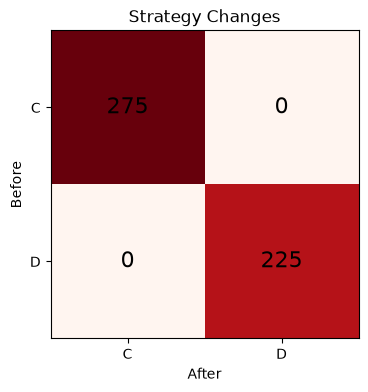

In [370]:
old_strategies = result[0]
new_strategies = result[1]

states = ["C", "D"]

matrix = [[0, 0], [0, 0]]  # List 1, List 2


for node in old_strategies:
    row = states.index(old_strategies[node])
    col = states.index(new_strategies[node])
    matrix[row][col] += 1
    # matrix[0][1] for example would go to the first list, second column to give us a cell and add 1 to that cell

# Plot the grid as a heatmap
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(matrix, cmap="Reds")
    # Write each count in its cell
for row in range(2):
    for col in range(2):
        ax.text(col, row, matrix[row][col], ha="center", va="center", fontsize=16)

ax.set_xticks([0, 1])
ax.set_xticklabels(states)
ax.set_yticks([0, 1])
ax.set_yticklabels(states)
ax.set_xlabel("After")
ax.set_ylabel("Before")
ax.set_title("Strategy Changes")
plt.show()

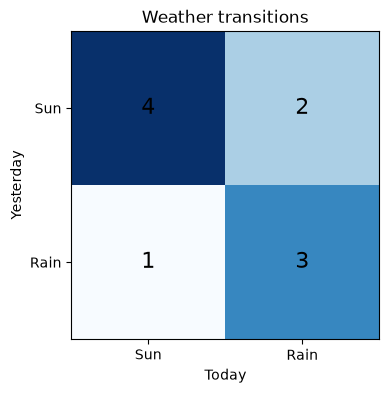

In [366]:
# Example Code
# Toy data: 10 days of weather, yesterday -> today
yesterday = {1: "Sun", 2: "Sun", 3: "Rain", 4: "Sun", 5: "Rain",
             6: "Rain", 7: "Sun", 8: "Sun", 9: "Rain", 10: "Sun"}
today     = {1: "Sun", 2: "Rain", 3: "Rain", 4: "Sun", 5: "Sun",
             6: "Rain", 7: "Sun", 8: "Rain", 9: "Rain", 10: "Sun"}

states = ["Sun", "Rain"]

# Build a 2x2 grid of counts: rows = yesterday, columns = today
matrix = [[0, 0],
          [0, 0]]

for day in yesterday:
    row = states.index(yesterday[day])
    col = states.index(today[day])
    matrix[row][col] += 1

# Plot the grid as a heatmap
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(matrix, cmap="Blues")

# Write each count in its cell
for row in range(2):
    for col in range(2):
        ax.text(col, row, matrix[row][col], ha="center", va="center", fontsize=16)

ax.set_xticks([0, 1])
ax.set_xticklabels(states)
ax.set_yticks([0, 1])
ax.set_yticklabels(states)
ax.set_xlabel("Today")
ax.set_ylabel("Yesterday")
ax.set_title("Weather transitions")
plt.show()

In [322]:
matrix

[[6, 269], [0, 225]]

In [326]:
row

1

In [327]:
old_strategies[0]

'D'

# **Full Simulation One Step**

## Setting Up Graph

In [377]:
G = setup_graph(network_type="lattice", N=100)

## Setting Up Parameters

In [378]:
setup_params(G, share = 0.05)

{6: {'group': 'C', 'color': 'tab:blue', 'payoff': 0},
 19: {'group': 'C', 'color': 'tab:blue', 'payoff': 0},
 32: {'group': 'C', 'color': 'tab:blue', 'payoff': 0},
 69: {'group': 'C', 'color': 'tab:blue', 'payoff': 0},
 37: {'group': 'C', 'color': 'tab:blue', 'payoff': 0},
 10: {'group': 'D', 'color': 'tab:red', 'payoff': 0},
 72: {'group': 'D', 'color': 'tab:red', 'payoff': 0},
 51: {'group': 'D', 'color': 'tab:red', 'payoff': 0},
 14: {'group': 'D', 'color': 'tab:red', 'payoff': 0},
 42: {'group': 'D', 'color': 'tab:red', 'payoff': 0},
 68: {'group': 'D', 'color': 'tab:red', 'payoff': 0},
 8: {'group': 'D', 'color': 'tab:red', 'payoff': 0},
 81: {'group': 'D', 'color': 'tab:red', 'payoff': 0},
 86: {'group': 'D', 'color': 'tab:red', 'payoff': 0},
 2: {'group': 'D', 'color': 'tab:red', 'payoff': 0},
 80: {'group': 'D', 'color': 'tab:red', 'payoff': 0},
 73: {'group': 'D', 'color': 'tab:red', 'payoff': 0},
 55: {'group': 'D', 'color': 'tab:red', 'payoff': 0},
 85: {'group': 'D', 'color

## Running One Step

In [379]:
results = pd_one_step(G, b = 1)

## Visualization

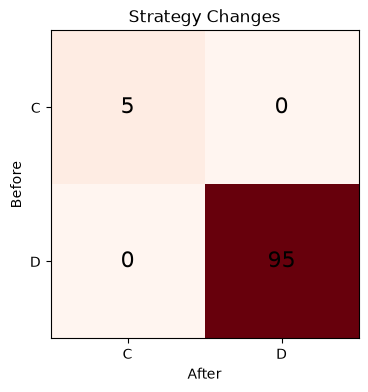

In [380]:
old_strategies = results[0]
new_strategies = results[1]

states = ["C", "D"]

matrix = [[0, 0], [0, 0]]  # List 1, List 2


for node in old_strategies:
    row = states.index(old_strategies[node])
    col = states.index(new_strategies[node])
    matrix[row][col] += 1
    # matrix[0][1] for example would go to the first list, second column to give us a cell and add 1 to that cell

# Plot the grid as a heatmap
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(matrix, cmap="Reds")
    # Write each count in its cell
for row in range(2):
    for col in range(2):
        ax.text(col, row, matrix[row][col], ha="center", va="center", fontsize=16)

ax.set_xticks([0, 1])
ax.set_xticklabels(states)
ax.set_yticks([0, 1])
ax.set_yticklabels(states)
ax.set_xlabel("After")
ax.set_ylabel("Before")
ax.set_title("Strategy Changes")
plt.show()